# Predict the halo observer’s Δv

**Goal:** predict the halo observer’s Δv vector needed to support Gateway tracking, using `narxpy`, and inspect prediction errors against the data.

**What the current targets actually represent:** the STM computes Δv to correct halo-reference departure. It does **not** optimize Gateway tracking error. This notebook tests whether NARX predicts those available Δv labels, and checks whether they support the intended tracking objective. That limitation must be visible before interpreting any prediction result.

In [1]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'configs').exists(): ROOT = ROOT.parent
os.chdir(ROOT)
from halo_tracking.study import load_config
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset
from halo_tracking.narx_audit import audit_dataset
from halo_tracking.two_stage_narx import fit_observer_policy
from halo_tracking.delta_v_prediction import fit_delta_v_predictor, delta_v_targets
cfg = load_config()
cfg['narx']['closed_loop_measurement_cadence_s'] = 21600.
OUT = ROOT/'artifacts'/'delta_v_prediction'
OUT.mkdir(parents=True, exist_ok=True)
dataset = ROOT/'artifacts'/'neural_narx'/'teacher_training'
nb00 = ROOT/'notebooks'/'00_gateway_tracking_comparison.ipynb'
original_hash = hashlib.sha256(nb00.read_bytes()).hexdigest()
if not all((dataset/(s+'.npz')).exists() for s in ('training','validation','test')):
    generate_closed_loop_dataset(cfg, dataset)
audit = audit_dataset(dataset, cfg)
print('Training / validation / test: 20 / 5 / 5 independent trajectories.')
print('Existing teacher data reused; units, histories and STM targets audited.')

Training / validation / test: 20 / 5 / 5 independent trajectories.
Existing teacher data reused; units, histories and STM targets audited.


## One prediction target

The output is **only** $\Delta v_k=[\Delta v_x,\Delta v_y,\Delta v_z]$ in rotating-frame m/s. A known no-command decision has a zero vector; a rejected required burn is unknown and excluded, not relabeled zero. The STM’s selected burn delay defines the label, but this model does not predict or change that delay.

Inputs are estimated halo departure (km and m/s), orbit phase, visibility, visible LSO count and position-covariance trace. The same four input taps and four **past Δv output** taps are used in training and prediction:

$$\widehat{\Delta v}_k=f_\theta(x_{k-3:k},\Delta v_{k-4:k-1}).$$

`narxpy.NARX(d_i=4, d_o=4, d_x=11, d_y=3, d_hl=64, act_func="Identity")` uses a tanh hidden layer and three linear outputs. Training-only scaling, 600 Adam epochs and validation checkpoint selection precede test evaluation. One-step prediction receives past true Δv; recursive prediction receives past predicted Δv, initialized to zero. The input indexing is shifted to include the current measurement; output feedback remains strictly past.

The existing gradient-boosted baseline is retained. Zero Δv and previous Δv are reference predictions: a model should improve on simple alternatives. Test trajectories are not used to fit weights, scales or select the checkpoint.

In [2]:
baseline = fit_observer_policy(dataset, cfg, OUT/'gradient_boosted.joblib')
model, report, predictions, data, masks = fit_delta_v_predictor(
    dataset, cfg, OUT, baseline, epochs=600)
print(f"Trained {report['epochs_trained']} epochs; validation selected epoch {report['selected_epoch']}.")
print(f"Network output: 3 Δv components; parameters: {report['parameters']}.")
display(Markdown('| Split | Arcs | Usable decisions | Nonzero Δv targets | Zero-target fraction |\n|---|---:|---:|---:|---:|\n'+'\n'.join(
    f"| {s} | {v['arcs']} | {v['decisions']} | {v['burn_examples']} | {v['no_burn_fraction']:.1%} |"
    for s,v in report['data_diagnostics'].items())))
print('Metrics below use the untouched test trajectories.')

Trained 600 epochs; validation selected epoch 69.
Network output: 3 Δv components; parameters: 3843.
Metrics below use the untouched test trajectories.


| Split | Arcs | Usable decisions | Nonzero Δv targets | Zero-target fraction |
|---|---:|---:|---:|---:|
| training | 20 | 260 | 41 | 84.2% |
| validation | 5 | 65 | 8 | 87.7% |
| test | 5 | 65 | 9 | 86.2% |

## Does NARX predict Δv accurately?

Errors are in **m/s**. Vector RMSE is the root mean squared three-dimensional vector error. The nonzero-target column matters: an average dominated by zero-command decisions can hide poor burn predictions. Recursive testing uses the model’s own output history while navigation inputs remain those of the held-out teacher trajectories.

| Prediction | All-target vector RMSE | Nonzero-target vector RMSE | Zero-target vector RMSE |
|---|---:|---:|---:|
| NARX one-step | 0.208 | 0.442 | 0.138 |
| NARX recursive | 0.230 | 0.514 | 0.138 |
| Gradient-boosted | 0.208 | 0.516 | 0.085 |
| Zero delta-v | 0.198 | 0.531 | 0.000 |
| Previous delta-v | 0.357 | 0.764 | 0.232 |

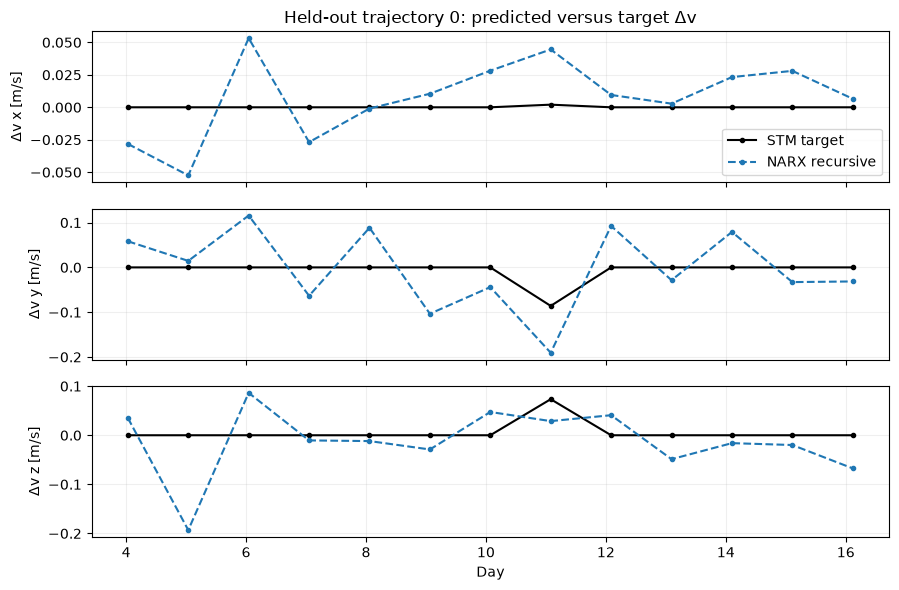

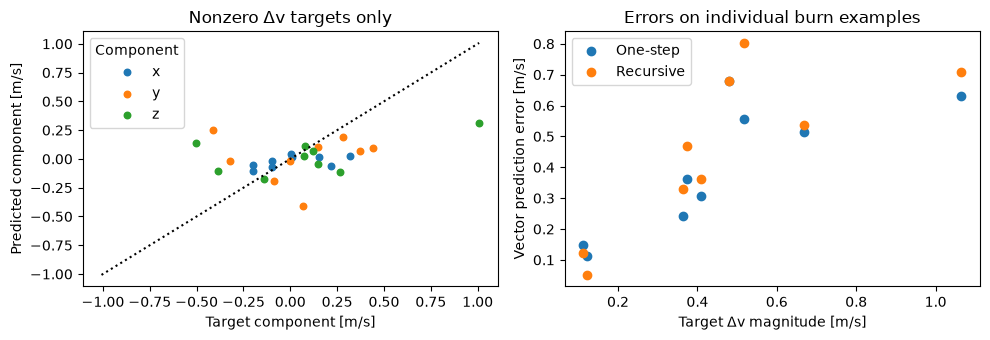

In [3]:
test = report['splits']['test']
rows = []
for name,m in test.items():
    burn = m['burn_vector_rmse_m_s']
    rows.append(f"| {name} | {m['vector_rmse_m_s']:.3f} | {burn:.3f} | {m['no_burn_vector_rmse_m_s']:.3f} |")
display(Markdown('| Prediction | All-target vector RMSE | Nonzero-target vector RMSE | Zero-target vector RMSE |\n|---|---:|---:|---:|\n'+'\n'.join(rows)))
saved = np.load(OUT/'held_out_predictions.npz')
truth, recursive, one_step = saved['target'], saved['recursive'], saved['one_step']
mask, burn, day = saved['mask'], saved['burn'], saved['day']
fig, axes = plt.subplots(3,1,figsize=(9,6),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(day[mask[0]],truth[0,mask[0],j],'ko-',ms=3,label='STM target')
    ax.plot(day[mask[0]],recursive[0,mask[0],j],'o--',ms=3,label='NARX recursive')
    ax.set_ylabel(['Δv x [m/s]','Δv y [m/s]','Δv z [m/s]'][j]); ax.grid(alpha=.2)
axes[0].set_title('Held-out trajectory 0: predicted versus target Δv')
axes[0].legend(); axes[-1].set_xlabel('Day')
fig.tight_layout(); fig.savefig(OUT/'delta_v_predictions.png',dpi=110); plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for j,label in enumerate(('x','y','z')):
    axes[0].scatter(truth[mask & burn,j],recursive[mask & burn,j],s=22,label=label)
limit = max(np.abs(truth[mask & burn]).max(),np.abs(recursive[mask & burn]).max())
axes[0].plot([-limit,limit],[-limit,limit],'k:')
axes[0].set(xlabel='Target component [m/s]',ylabel='Predicted component [m/s]',title='Nonzero Δv targets only')
axes[0].legend(title='Component')
for name,pred in [('One-step',one_step),('Recursive',recursive)]:
    e = np.linalg.norm(pred-truth,axis=-1)
    axes[1].scatter(np.linalg.norm(truth[mask & burn],axis=-1),e[mask & burn],label=name)
axes[1].set(xlabel='Target Δv magnitude [m/s]',ylabel='Vector prediction error [m/s]',title='Errors on individual burn examples')
axes[1].legend(); fig.tight_layout(); fig.savefig(OUT/'delta_v_errors.png',dpi=110); plt.show()

## Do these Δv labels represent Gateway tracking needs?

The existing teacher minimizes weighted **halo position and velocity departure**, using 100 km / 1 m/s halo limits. It does not minimize Gateway tracking error or enforce the 100 m / 0.01 m/s tracking thresholds. The plot below compares its commands with the actual simulated Gateway estimation error. This is a label/objective check, not evidence that a particular burn causes tracking improvement.

Usable training data: 41 nonzero Δv examples across 20 independent trajectories.
Held-out nonzero Δv examples: 9; recursive NARX / zero / boosted vector RMSE: 0.514 / 0.531 / 0.516 m/s.
Tracking limits exceeded at 31 usable test decisions; the teacher issued no burn at 26 of those decisions.
Notebook 00 unchanged.
Out[4]: 1421


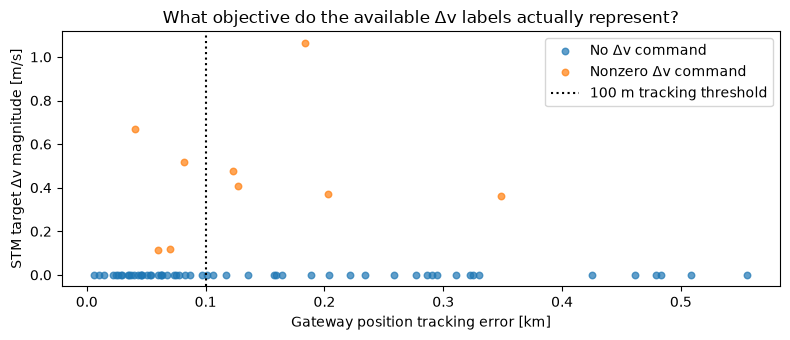

**Measured finding:** Recursive NARX vector RMSE is 0.230 m/s across all test decisions, compared with 0.198 m/s for zero Δv. On the nine nonzero targets, its error is 0.514 m/s versus 0.531 m/s for zero Δv. Burn prediction error increases by 16.4% when past predictions replace past true Δv.

**What the data explain:** most targets are zero; only 41 usable nonzero training examples support 3843 parameters. The model has weak overall predictive performance here, and recursive feedback increases burn error. These observations identify limitations; they do not prove which data deficiency caused each error. The targets also describe halo correction rather than the Δv required to satisfy Gateway tracking limits. Consequently these labels cannot establish reliability for the intended tracking objective.

In [4]:
d = data['test']
y,known,active = delta_v_targets(d)
tracking = d['gateway_tracking_position_error_km']
fig,ax = plt.subplots(figsize=(8,3.5))
for select,label in [(mask & ~active,'No Δv command'),(mask & active,'Nonzero Δv command')]:
    ax.scatter(tracking[select],np.linalg.norm(y[select],axis=-1),s=22,label=label,alpha=.7)
ax.axvline(.1,color='k',ls=':',label='100 m tracking threshold')
ax.set(xlabel='Gateway position tracking error [km]',ylabel='STM target Δv magnitude [m/s]',
       title='What objective do the available Δv labels actually represent?')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'tracking_label_check.png',dpi=110); plt.show()
diag = report['data_diagnostics']
train,held = diag['training'],diag['test']
a = test['NARX recursive']['burn_vector_rmse_m_s']
z = test['Zero delta-v']['burn_vector_rmse_m_s']
g = test['Gradient-boosted']['burn_vector_rmse_m_s']
print(f"Usable training data: {train['burn_examples']} nonzero Δv examples across {train['arcs']} independent trajectories.")
print(f"Held-out nonzero Δv examples: {held['burn_examples']}; recursive NARX / zero / boosted vector RMSE: {a:.3f} / {z:.3f} / {g:.3f} m/s.")
print(f"Tracking limits exceeded at {held['tracking_limit_exceeded_decisions']} usable test decisions; the teacher issued no burn at {held['tracking_limit_exceeded_without_command']} of those decisions.")
all_narx = test['NARX recursive']['vector_rmse_m_s']
all_zero = test['Zero delta-v']['vector_rmse_m_s']
one_burn = test['NARX one-step']['burn_vector_rmse_m_s']
change = (a/one_burn-1)*100
finding = (f'Recursive NARX vector RMSE is {all_narx:.3f} m/s across all test decisions, '
    f'compared with {all_zero:.3f} m/s for zero Δv. On the nine nonzero targets, '
    f'its error is {a:.3f} m/s versus {z:.3f} m/s for zero Δv. '
    f'Burn prediction error increases by {change:.1f}% when past predictions replace past true Δv.')
display(Markdown('**Measured finding:** '+finding+'\n\n'
    '**What the data explain:** most targets are zero; only '+str(train['burn_examples'])+
    ' usable nonzero training examples support '+str(report['parameters'])+' parameters. '
    'The model has weak overall predictive performance here, and recursive feedback increases burn error. '
    'These observations identify limitations; they do not prove which data deficiency caused each error. '
    'The targets also describe halo correction rather than the Δv required to satisfy Gateway tracking limits. '
    'Consequently these labels cannot establish reliability for the intended tracking objective.'))
assert hashlib.sha256(nb00.read_bytes()).hexdigest() == original_hash
print('Notebook 00 unchanged.')
(OUT/'audit.json').write_text(json.dumps(audit,indent=2)+'\n')

**Scope of the conclusion:** this is a Δv prediction experiment and a diagnosis of the available data. It does not assume that NARX must fail. A claim about predicting the Δv *required to maintain Gateway tracking* needs teacher targets tied to that tracking objective. The earlier annual controller comparison remains saved separately; it is not rerun or used as proof of prediction accuracy here.